# Revision analyses: rhythm features in North & East Indian folk music (CICT-2026, paper 955)

Re-runs the analyses the reviewers questioned, treating the **song** (160 units) as the independent unit.
Input: your segment-level feature table (one row per segment, 33 usable rhythm parameters + genre + song id).
If the extraction notebook left a DataFrame called `df` in memory, it is used as is; otherwise set `FEATURES_PATH`.

| Reviewer point | Section |
|---|---|
| R1.1, R4 pseudoreplication | 1 (dependence), 2 (song-level stats, post-hoc, all 33 parameters) |
| R1.2, R4 cosine near zero | 3 (cosine at song-centroid level, permutation test, overlap) |
| R1.1, R4 K-NN leakage and chance | 4 (same-song neighbours excluded, prior-aware chance) |
| R4 PCA numbers | 5 |
| R1.2, R4 single held-out split | 6 (repeated song-grouped splits, intervals, per-genre F1, confusions) |

In [1]:
import itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, confusion_matrix
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50)

# ---- CONFIG ----
FEATURES_PATH = "../data/extracted/rhythm_features.parquet"      # .csv or .parquet, one row per segment
GENRE_COL, SONG_COL = "genre", "song_id"
ARTIST_COL = "artist"               # optional; if present, an artist-grouped run is added
EXTRA_META = []                     # any other non-feature numeric columns to ignore
SEED = 42
N_PERM = 5000                       # permutation draws for the cosine test
KNN_QUERY_PER_SONG = 100            # query segments sampled per song
N_REPEATS = 20                      # repeated grouped train/test splits
TEST_FRAC = 0.20                    # per-genre fraction of songs held out (4 of 20)
TRAIN_PER_SONG = 100                # cap on training segments per song; None = use all (slow for SVM)
RNG = np.random.default_rng(SEED)

In [6]:
df = pd.read_parquet(FEATURES_PATH)

print(f"Loaded: {FEATURES_PATH}")
print(f"Shape: {df.shape}")
print("\nColumns:")
print(df.columns.tolist())

column_map = {str(c).strip().lower(): c for c in df.columns}

genre_candidates = ["folk_style", "genre", "style"]
song_candidates = ["song", "song_name", "songname", "track", "track_name"]
artist_candidates = ["artist", "artist_name"]

GENRE_COL = next(
    (column_map[c] for c in genre_candidates if c in column_map),
    None
)

SONG_COL = next(
    (column_map[c] for c in song_candidates if c in column_map),
    None
)

ARTIST_COL = next(
    (column_map[c] for c in artist_candidates if c in column_map),
    None
)

print("\nDetected columns:")
print("Genre :", GENRE_COL)
print("Song  :", SONG_COL)
print("Artist:", ARTIST_COL)

assert GENRE_COL is not None, "Could not find the genre column."
assert SONG_COL is not None, "Could not find the song column."

EXTRA_META = {
    c for c in ["state", "gender", "source"]
    if c in df.columns
}

df["song_id"] = (
    df[GENRE_COL].astype(str)
    + "|"
    + df[SONG_COL].astype(str)
)

if ARTIST_COL is not None:
    df["artist_key"] = (
        df[GENRE_COL].astype(str)
        + "|"
        + df[ARTIST_COL].astype(str)
    )

meta = {
    GENRE_COL,
    SONG_COL,
    "song_id",
    "artist_key",
    *EXTRA_META
}

if ARTIST_COL is not None:
    meta.add(ARTIST_COL)

cand = [
    c for c in df.select_dtypes(include="number").columns
    if c not in meta
]

df[cand] = df[cand].replace([np.inf, -np.inf], np.nan)

bad = df[cand].isna().any(axis=1)

print(f"\nRows with NaN/inf in any feature: {bad.sum()} (dropped)")

df = df.loc[~bad].reset_index(drop=True)

FEATS = [
    c for c in cand
    if df[c].nunique() > 1
]

print(
    "Constant features excluded:",
    [c for c in cand if c not in FEATS]
)

print(f"\n{len(FEATS)} usable features (paper: 33)")
print(FEATS)

genres = sorted(df[GENRE_COL].unique())

song_c = pd.factorize(df["song_id"])[0]
gen_c = pd.factorize(df[GENRE_COL], sort=True)[0]

cnt = np.bincount(song_c)

song_gen = (
    pd.Series(gen_c)
    .groupby(song_c)
    .first()
    .values
)

Z = StandardScaler().fit_transform(df[FEATS])

summary = df.groupby(GENRE_COL).agg(
    songs=("song_id", "nunique"),
    segments=(GENRE_COL, "size")
)

summary["segment_share_%"] = (
    100 * summary.segments / len(df)
).round(1)

print("\nSummary:")
print(summary)

print(
    f"\nTotal: {df['song_id'].nunique()} songs, "
    f"{len(df):,} segments"
)

Loaded: ../data/extracted/rhythm_features.parquet
Shape: (109089, 41)

Columns:
['genre', 'state', 'artist', 'gender', 'song', 'source', 'source_file', 'energy_mean', 'energy_std', 'energy_max', 'energy_min', 'energy_range', 'energy_skew', 'flux_mean', 'flux_std', 'flux_max', 'flux_sum', 'ac_peak_lag', 'ac_peak_value', 'ac_mean', 'ac_std', 'temporal_entropy', 'frame_entropy_mean', 'frame_entropy_std', 'modulation_dominant_freq_bin', 'modulation_dominant_mag', 'modulation_energy', 'modulation_centroid', 'rhythm_hist_dominant_bin', 'rhythm_hist_dominant_value', 'rhythm_hist_entropy', 'rhythm_hist_std', 'tempogram_dominant_lag', 'tempogram_stability', 'tempogram_mean_energy', 'tempogram_var', 'onset_mean', 'onset_std', 'onset_max', 'onset_peak_count', 'onset_density']

Detected columns:
Genre : genre
Song  : song
Artist: artist

Rows with NaN/inf in any feature: 0 (dropped)
Constant features excluded: ['tempogram_stability']

33 usable features (paper: 33)
['energy_mean', 'energy_std', 'e

## 1. How dependent are segments within a song? (ICC and effective sample size)

In [11]:
def icc1(x, g):
    x = pd.Series(np.asarray(x)); g = pd.Series(np.asarray(g))
    grp = x.groupby(g); n_i = grp.size().values; k = len(n_i); N = n_i.sum()
    ssb = (n_i * (grp.mean().values - x.mean()) ** 2).sum()
    ssw = ((x - grp.transform("mean")) ** 2).sum()
    msb, msw = ssb / (k - 1), ssw / (N - k)
    n0 = (N - (n_i ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)

icc = pd.Series({f: icc1(df[f], song_c) for f in FEATS})
nbar = len(df) / df.song.nunique()
deff = 1 + (nbar - 1) * icc.clip(lower=0)
print(f"ICC(song) per feature: median {icc.median():.2f}, range {icc.min():.2f} to {icc.max():.2f}")
print(f"Design effect (median) {deff.median():.0f}  ->  effective n ~ {len(df) / deff.median():,.0f} of {len(df):,} segments")

ICC(song) per feature: median 0.30, range 0.01 to 0.75
Design effect (median) 208  ->  effective n ~ 525 of 109,089 segments


## 2. Song-level statistics: Kruskal-Wallis with eta-squared, BH-FDR, all parameters, post-hoc

In [12]:
def bh(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    r = np.empty_like(o)
    r[o] = np.arange(len(p))
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    return np.minimum(np.minimum.accumulate(q[::-1])[::-1], 1)[r]


S = df.groupby([GENRE_COL, SONG_COL])[FEATS].median().reset_index()

k, n = len(genres), len(S)

rows = []
skipped = []

song_groups = [
    g for _, g in S.groupby(GENRE_COL)
]

segment_groups = [
    g for _, g in df.groupby(GENRE_COL)
]

for f in FEATS:
    song_values = [g[f].values for g in song_groups]
    segment_values = [g[f].values for g in segment_groups]

    song_all = np.concatenate(song_values)
    segment_all = np.concatenate(segment_values)

    if np.all(song_all == song_all[0]):
        skipped.append((f, "all song-level values identical"))
        continue

    if np.all(segment_all == segment_all[0]):
        skipped.append((f, "all segment-level values identical"))
        continue

    try:
        H, p = stats.kruskal(*song_values)
        Hs, _ = stats.kruskal(*segment_values)
    except ValueError as e:
        skipped.append((f, str(e)))
        continue

    rows.append({
        "feature": f,
        "H_song": H,
        "p_song": p,
        "eta2_song": (H - k + 1) / (n - k),
        "eta2_segment": (Hs - k + 1) / (len(df) - k),
        "ICC": icc[f]
    })


T = pd.DataFrame(rows)

if len(T) > 0:
    T["p_fdr"] = bh(T["p_song"])

    T = (
        T.sort_values("eta2_song", ascending=False)
        .reset_index(drop=True)
    )

    print(
        f"Song-level (n={n}): "
        f"{(T.p_fdr < .05).sum()} of {len(T)} "
        f"parameters significant after BH-FDR (q<.05)"
    )

    print(
        f"max eta2 song-level {T.eta2_song.max():.3f} | "
        f"segment-level {T.eta2_segment.max():.3f}"
    )

    T.round(4).to_csv(
        "table_all_parameters_song_level.csv",
        index=False
    )

    display(T.round(4))
else:
    print("No features could be tested.")

print(f"\nSkipped features: {len(skipped)}")

if skipped:
    print("\nSkipped feature details:")
    for feature, reason in skipped:
        print(f"  {feature}: {reason}")

Song-level (n=160): 24 of 30 parameters significant after BH-FDR (q<.05)
max eta2 song-level 0.236 | segment-level 0.155


,feature,H_song,p_song,eta2_song,eta2_segment,ICC,p_fdr
0,energy_min,42.8562,0.0000,0.2359,0.1553,0.4527,0.0000
1,tempogram_var,34.3434,0.0000,0.1799,0.0862,0.2513,0.0002
2,energy_mean,32.9439,0.0000,0.1707,0.1441,0.6338,0.0003
3,frame_entropy_mean,30.2476,0.0001,0.1529,0.1495,0.7529,0.0006
4,energy_max,29.4402,0.0001,0.1476,0.1378,0.6874,0.0007
5,rhythm_hist_dominant_value,27.5987,0.0003,0.1355,0.0703,0.3095,0.0013
6,modulation_centroid,26.8987,0.0003,0.1309,0.0660,0.2384,0.0015
7,energy_range,22.9579,0.0017,0.1050,0.0584,0.2796,0.0055
8,onset_peak_count,22.8037,0.0018,0.1040,0.0670,0.3230,0.0055
9,onset_density,22.8037,0.0018,0.1040,0.0670,0.3230,0.0055



Skipped features: 3

Skipped feature details:
  ac_peak_lag: all song-level values identical
  tempogram_dominant_lag: all song-level values identical
  tempogram_mean_energy: all song-level values identical


In [13]:
pairs = list(itertools.combinations(genres, 2)); rows = []
for f in FEATS:
    for a, b in pairs:
        x = S.loc[S[GENRE_COL] == a, f].values; y = S.loc[S[GENRE_COL] == b, f].values
        U, p = stats.mannwhitneyu(x, y, alternative="two-sided")
        rows.append((f, a, b, p, 2 * U / (len(x) * len(y)) - 1))
P = pd.DataFrame(rows, columns=["feature", "genre_a", "genre_b", "p", "rank_biserial"])
P["p_fdr"] = bh(P.p)                                   # BH over all feature x pair tests
P.round(5).to_csv("table_posthoc_pairwise_song_level.csv", index=False)
M = P.assign(sig=P.p_fdr < .05).groupby(["genre_a", "genre_b"]).sig.sum().unstack()
print(f"Number of parameters (of {len(FEATS)}) differing between each genre pair (song-level MWU, BH-FDR q<.05):")
display(M.fillna(""))
print("Median |rank-biserial| over significant tests:", P.loc[P.p_fdr < .05, "rank_biserial"].abs().median().round(2))

Number of parameters (of 33) differing between each genre pair (song-level MWU, BH-FDR q<.05):


genre_b,Bhatiali,Gidha,Kajri,Maand,Sohar,Sufi,Uttarakhandi
genre_a,,,,,,,
Bauls,1.0,1.0,1.0,2.0,1.0,3.0,5.0
Bhatiali,,7.0,2.0,1.0,2.0,3.0,2.0
Gidha,,,0.0,3.0,2.0,2.0,7.0
Kajri,,,,0.0,2.0,0.0,0.0
Maand,,,,,2.0,0.0,0.0
Sohar,,,,,,7.0,8.0
Sufi,,,,,,,0.0


Median |rank-biserial| over significant tests: 0.6


## 3. Cosine similarity: what is compared, and is the gap real?

SONG-CENTROID cosine (song pairs)
  within-genre mean 0.107 | across-genre mean -0.006 | difference 0.113
  P(within pair > across pair) = 0.57 | label-permutation p = 0.0002 (5000 draws)

SEGMENT-PAIR cosine (random pairs)
  same song 0.373 | same genre, different song 0.045 | different genre 0.003
  P(same-genre pair > different-genre pair), same-song pairs excluded = 0.53


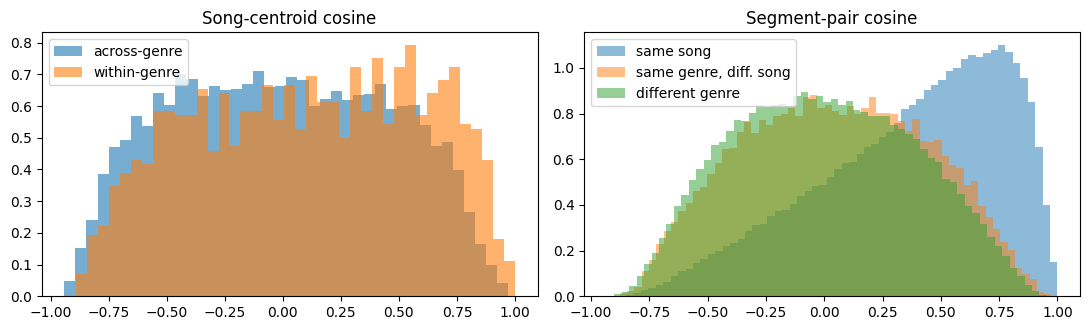

In [14]:
# (a) Song-level: each song -> centroid of its z-scored segments; compare centroids
C = pd.DataFrame(Z).groupby(song_c).mean().values
Cn = C / np.linalg.norm(C, axis=1, keepdims=True); CS = Cn @ Cn.T
iu = np.triu_indices(len(Cn), 1); vals = CS[iu]
same = (song_gen[:, None] == song_gen[None, :])[iu]
w, a = vals[same], vals[~same]
auc = stats.mannwhitneyu(w, a).statistic / (len(w) * len(a))
obs = w.mean() - a.mean(); perm = np.empty(N_PERM)
for i in range(N_PERM):
    lab = RNG.permutation(song_gen); s = (lab[:, None] == lab[None, :])[iu]
    perm[i] = vals[s].mean() - vals[~s].mean()
p_perm = (1 + (perm >= obs).sum()) / (N_PERM + 1)
print("SONG-CENTROID cosine (song pairs)")
print(f"  within-genre mean {w.mean():.3f} | across-genre mean {a.mean():.3f} | difference {obs:.3f}")
print(f"  P(within pair > across pair) = {auc:.2f} | label-permutation p = {p_perm:.4f} ({N_PERM} draws)")

# (b) Segment-level pairs, separating same-song pairs from different-song pairs
M_ = 200_000
order = np.argsort(song_c, kind="stable"); starts = np.r_[0, np.cumsum(cnt)[:-1]]
Zn = Z / np.linalg.norm(Z, axis=1, keepdims=True)
i = RNG.integers(0, len(Z), M_); j = RNG.integers(0, len(Z), M_)
cs = (Zn[i] * Zn[j]).sum(1); ss = song_c[i] == song_c[j]; sg = gen_c[i] == gen_c[j]
js = order[starts[song_c[i]] + (RNG.random(M_) * cnt[song_c[i]]).astype(int)]
cs_same_song = (Zn[i] * Zn[js]).sum(1)
wg, ag = cs[sg & ~ss], cs[~sg]
auc_seg = stats.mannwhitneyu(wg, ag).statistic / (len(wg) * len(ag))
print("\nSEGMENT-PAIR cosine (random pairs)")
print(f"  same song {cs_same_song.mean():.3f} | same genre, different song {wg.mean():.3f} | different genre {ag.mean():.3f}")
print(f"  P(same-genre pair > different-genre pair), same-song pairs excluded = {auc_seg:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(a, 40, alpha=.6, density=True, label="across-genre"); ax[0].hist(w, 40, alpha=.6, density=True, label="within-genre")
ax[0].set_title("Song-centroid cosine"); ax[0].legend()
for v, l in [(cs_same_song, "same song"), (wg, "same genre, diff. song"), (ag, "different genre")]:
    ax[1].hist(v, 60, alpha=.5, density=True, label=l)
ax[1].set_title("Segment-pair cosine"); ax[1].legend(); plt.tight_layout(); plt.show()

## 4. K-NN cohesion with same-song neighbours excluded, and prior-aware chance

In [15]:
K = 5
qidx = np.concatenate([RNG.choice(np.where(song_c == s)[0], min(KNN_QUERY_PER_SONG, cnt[s]), replace=False)
                       for s in range(len(cnt))])
qsong = song_c[qidx]

# (a) as in the paper: neighbours drawn from all segments (own song included; self dropped)
ind = NearestNeighbors(n_neighbors=K + 1, algorithm="brute", n_jobs=-1).fit(Z).kneighbors(Z[qidx], return_distance=False)[:, 1:]
agree_orig = (gen_c[ind] == gen_c[qidx, None]).mean(1)
print(f"Share of neighbours that come from the query's own song (paper protocol): {(song_c[ind] == qsong[:, None]).mean():.1%}")

# (b) same-song neighbours excluded: each song queried against all OTHER songs
agree_ex = np.empty(len(qidx)); chance = np.empty(len(qidx))
for s in range(len(cnt)):
    pos = np.where(qsong == s)[0]; pool = np.where(song_c != s)[0]
    nbr = NearestNeighbors(n_neighbors=K, algorithm="brute").fit(Z[pool]).kneighbors(Z[qidx[pos]], return_distance=False)
    agree_ex[pos] = (gen_c[pool][nbr] == song_gen[s]).mean(1)
    chance[pos] = (gen_c[pool] == song_gen[s]).mean()              # share of the pool with the query's genre

R = pd.DataFrame({"genre": np.array(genres)[gen_c[qidx]], "paper_protocol": agree_orig,
                  "same_song_excluded": agree_ex, "chance_prior_aware": chance})
R = R.groupby("genre").mean()
R["excess_over_chance"] = R.same_song_excluded - R.chance_prior_aware
print("Mean K-NN neighbour agreement (k=5)"); display((R * 100).round(1).sort_values("same_song_excluded", ascending=False))
print(f"Overall: paper protocol {agree_orig.mean():.1%} -> same-song excluded {agree_ex.mean():.1%} (prior-aware chance {chance.mean():.1%}; naive 12.5%)")

Share of neighbours that come from the query's own song (paper protocol): 49.9%
Mean K-NN neighbour agreement (k=5)


,paper_protocol,same_song_excluded,chance_prior_aware,excess_over_chance
genre,,,,
Sohar,63.7,40.6,11.4,29.2
Gidha,68.9,32.3,7.2,25.1
Uttarakhandi,72.0,28.7,11.4,17.3
Sufi,67.5,28.1,16.9,11.2
Maand,57.0,25.0,15.6,9.3
Kajri,58.8,24.9,18.1,6.8
Bhatiali,60.9,21.6,7.7,13.9
Bauls,48.8,14.0,7.4,6.7


Overall: paper protocol 62.2% -> same-song excluded 26.9% (prior-aware chance 12.0%; naive 12.5%)


## 5. PCA numbers (to reconcile Section V-B with Fig. 5 and Fig. 6)

In [16]:
ev = PCA().fit(Z).explained_variance_ratio_; cum = np.cumsum(ev)
print(f"PC1 {ev[0]:.1%} | PC2 {ev[1]:.1%} | PC1+PC2 {cum[1]:.1%} | PC3 {ev[2]:.1%}")
print(f"Cumulative at 5 PCs {cum[4]:.1%}, 10 PCs {cum[9]:.1%}, 15 PCs {cum[14]:.1%}")
print(f"Components for 80% / 90% / 95%: {np.searchsorted(cum, .80) + 1} / {np.searchsorted(cum, .90) + 1} / {np.searchsorted(cum, .95) + 1}")

PC1 27.9% | PC2 21.7% | PC1+PC2 49.6% | PC3 8.9%
Cumulative at 5 PCs 70.7%, 10 PCs 87.1%, 15 PCs 95.2%
Components for 80% / 90% / 95%: 8 / 12 / 15


## 6. Repeated song-grouped splits: uncertainty for the held-out result
Each repeat holds out `TEST_FRAC` of the *groups* in every genre (4 of 20 songs), trains on the rest, tests on all held-out segments.
Intervals are the 2.5-97.5 percentile range across repeats; repeats share training songs, so this describes split-to-split variability, not a formal CI.

In [18]:
y = gen_c
X = df[FEATS].values

has_artist = ARTIST_COL in df.columns

def make_split(group_col, rng):
    g = df[[GENRE_COL, group_col]].drop_duplicates()
    test = []

    for _, sub in g.groupby(GENRE_COL):
        ids = sub[group_col].values
        n_test = max(1, int(round(TEST_FRAC * len(ids))))
        test += list(rng.choice(ids, n_test, replace=False))

    return df[group_col].isin(test).values


MODELS = {
    "SVM (RBF)": lambda: SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=SEED
    ),
    "Dummy (stratified)": lambda: DummyClassifier(
        strategy="stratified",
        random_state=SEED
    ),
    "Dummy (most frequent)": lambda: DummyClassifier(
        strategy="most_frequent"
    ),
}


def run(group_col):
    rng = np.random.default_rng(SEED)
    recs = []
    cms = {m: 0 for m in MODELS}
    f1g = []

    for r in range(N_REPEATS):
        te = make_split(group_col, rng)

        tr_idx = np.where(~te)[0]
        te_idx = np.where(te)[0]

        if TRAIN_PER_SONG:
            perm = rng.permutation(tr_idx)

            rank = (
                pd.Series(perm)
                .groupby(song_c[perm])
                .cumcount()
                .values
            )

            tr_idx = perm[rank < TRAIN_PER_SONG]

        sc = StandardScaler().fit(X[tr_idx])

        Xtr = sc.transform(X[tr_idx])
        Xte = sc.transform(X[te_idx])

        for name, mk in MODELS.items():

            model = mk()

            pred = (
                model
                .fit(Xtr, y[tr_idx])
                .predict(Xte)
            )

            t = pd.DataFrame({
                "s": song_c[te_idx],
                "y": y[te_idx],
                "p": pred
            })

            vote = (
                t.groupby("s")
                .p
                .agg(lambda v: v.value_counts().idxmax())
            )

            truth = (
                t.groupby("s")
                .y
                .first()
            )

            recs.append({
                "model": name,
                "rep": r,
                "acc": (pred == y[te_idx]).mean(),
                "macro_f1": f1_score(
                    y[te_idx],
                    pred,
                    average="macro",
                    labels=range(len(genres)),
                    zero_division=0
                ),
                "song_vote_acc": (vote == truth).mean()
            })

            cms[name] = (
                cms[name]
                + confusion_matrix(
                    y[te_idx],
                    pred,
                    labels=range(len(genres))
                )
            )

            f1g.append({
                "model": name,
                **dict(
                    zip(
                        genres,
                        f1_score(
                            y[te_idx],
                            pred,
                            average=None,
                            labels=range(len(genres)),
                            zero_division=0
                        )
                    )
                )
            })

    return (
        pd.DataFrame(recs),
        cms,
        pd.DataFrame(f1g)
    )


def report(res, label):
    q = lambda s: (
        f"{s.mean():.3f} "
        f"({s.quantile(.025):.3f}-"
        f"{s.quantile(.975):.3f})"
    )

    out = (
        res.groupby("model")
        .agg(
            accuracy=("acc", q),
            macro_F1=("macro_f1", q),
            song_vote_accuracy=("song_vote_acc", q)
        )
    )

    print(
        f"\n=== Grouped by {label}: "
        f"{N_REPEATS} repeated splits, "
        f"mean (2.5-97.5 pct) ==="
    )

    display(out)


RUNS = {
    "song": run(SONG_COL)
}

if has_artist:
    RUNS["artist"] = run("artist_key")

for lab, (res, cms, f1g) in RUNS.items():
    report(res, lab)


=== Grouped by song: 20 repeated splits, mean (2.5-97.5 pct) ===


,accuracy,macro_F1,song_vote_accuracy
model,,,
Dummy (most frequent),0.074 (0.058-0.085),0.017 (0.014-0.020),0.125 (0.125-0.125)
Dummy (stratified),0.124 (0.120-0.127),0.119 (0.115-0.123),0.133 (0.077-0.204)
Random Forest,0.320 (0.244-0.401),0.319 (0.237-0.394),0.527 (0.327-0.723)
SVM (RBF),0.335 (0.273-0.418),0.333 (0.276-0.407),0.556 (0.420-0.735)



=== Grouped by artist: 20 repeated splits, mean (2.5-97.5 pct) ===


,accuracy,macro_F1,song_vote_accuracy
model,,,
Dummy (most frequent),0.052 (0.020-0.158),0.012 (0.005-0.034),0.059 (0.027-0.142)
Dummy (stratified),0.119 (0.116-0.124),0.111 (0.105-0.118),0.077 (0.027-0.133)
Random Forest,0.230 (0.141-0.303),0.199 (0.131-0.256),0.264 (0.144-0.362)
SVM (RBF),0.272 (0.181-0.349),0.237 (0.172-0.297),0.352 (0.225-0.473)


Per-genre F1 (SVM), mean and SD over repeats:


,Bauls,Bhatiali,Gidha,Kajri,Maand,Sohar,Sufi,Uttarakhandi
mean,0.22,0.22,0.44,0.28,0.34,0.46,0.33,0.38
std,0.07,0.08,0.10,0.07,0.10,0.10,0.11,0.09


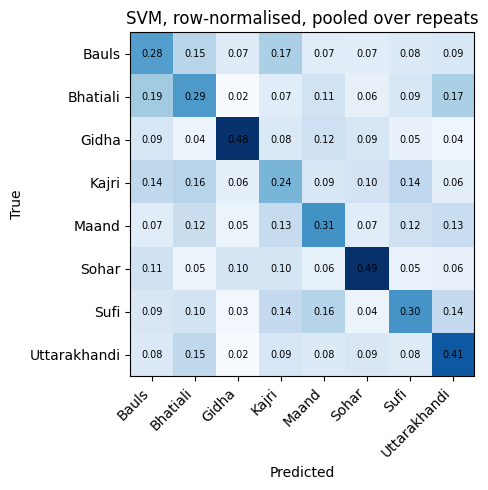

Largest off-diagonal confusions (true -> predicted):
      Bhatiali -> Bauls        0.19
         Bauls -> Kajri        0.17
      Bhatiali -> Uttarakhandi 0.17
          Sufi -> Maand        0.16
         Kajri -> Bhatiali     0.16
         Bauls -> Bhatiali     0.15
  Uttarakhandi -> Bhatiali     0.15
         Kajri -> Bauls        0.14


In [19]:
res, cms, f1g = RUNS["song"]
print("Per-genre F1 (SVM), mean and SD over repeats:")
display(f1g[f1g.model == "SVM (RBF)"].drop(columns="model").agg(["mean", "std"]).round(2))
cm = cms["SVM (RBF)"]; cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(cmn, cmap="Blues"); ax.set_xticks(range(len(genres)), genres, rotation=45, ha="right"); ax.set_yticks(range(len(genres)), genres)
for i_, j_ in itertools.product(range(len(genres)), repeat=2):
    ax.text(j_, i_, f"{cmn[i_, j_]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i_, j_] > .5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("SVM, row-normalised, pooled over repeats"); plt.tight_layout(); plt.show()
off = [(genres[i_], genres[j_], cmn[i_, j_]) for i_ in range(len(genres)) for j_ in range(len(genres)) if i_ != j_]
print("Largest off-diagonal confusions (true -> predicted):")
for a_, b_, v in sorted(off, key=lambda t: -t[2])[:8]: print(f"  {a_:>12} -> {b_:<12} {v:.2f}")